In [4]:
import pandas as pd

In [5]:
df =  pd.read_csv("../dataset/student_performance_factors.csv")
df.head()


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [6]:
df.shape

(6607, 20)

In [7]:
df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [12]:
df["Teacher_Quality"] = df["Teacher_Quality"].fillna(df["Teacher_Quality"].mode()[0])
df["Parental_Education_Level"] = df["Parental_Education_Level"].fillna(df["Parental_Education_Level"].mode()[0])
df["Distance_from_Home"] = df["Distance_from_Home"].fillna(df["Distance_from_Home"].mode()[0])

In [13]:
df.isnull().sum()

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64

In [14]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [15]:
df[["Attendance", "Exam_Score"]].corr()

,Attendance,Exam_Score
Attendance,1.000000,0.581072
Exam_Score,0.581072,1.000000


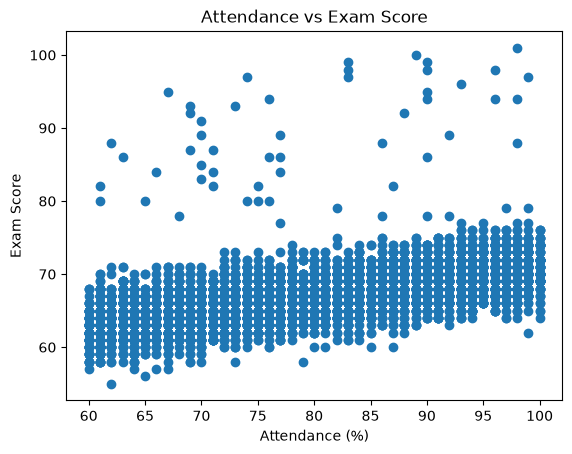

In [16]:
import matplotlib.pyplot as plt

plt.scatter(df["Attendance"], df["Exam_Score"])
plt.xlabel("Attendance (%)")
plt.ylabel("Exam Score")
plt.title("Attendance vs Exam Score")
plt.show()

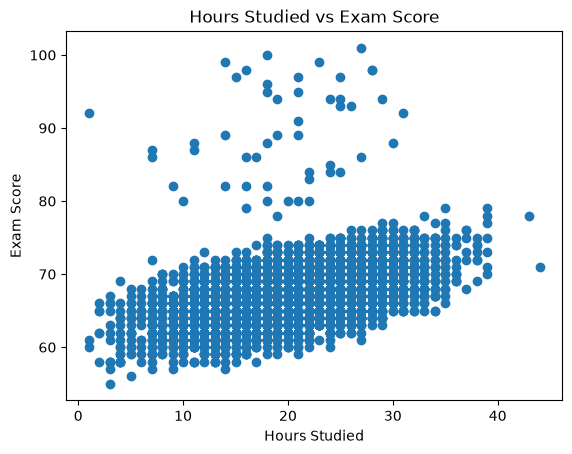

In [17]:
plt.scatter(df["Hours_Studied"], df["Exam_Score"])
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Hours Studied vs Exam Score")
plt.show()

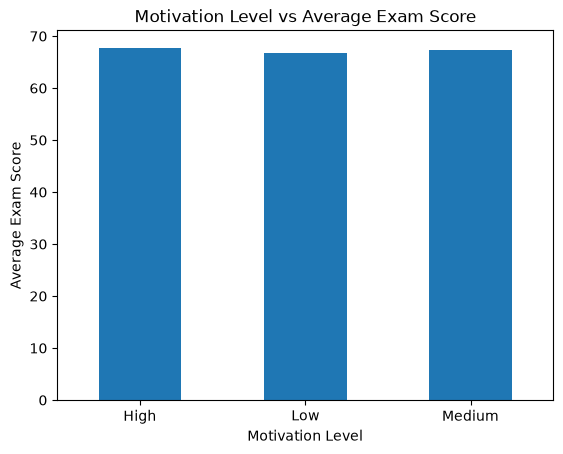

In [18]:
motivation_scores = df.groupby("Motivation_Level")["Exam_Score"].mean()

motivation_scores.plot(kind="bar")
plt.xlabel("Motivation Level")
plt.ylabel("Average Exam Score")
plt.title("Motivation Level vs Average Exam Score")
plt.xticks(rotation=0)
plt.show()

In [19]:
motivation_scores

Motivation_Level
High      67.704321
Low       66.752194
Medium    67.330648
Name: Exam_Score, dtype: float64

In [20]:
df[["Previous_Scores", "Exam_Score"]].corr()

,Previous_Scores,Exam_Score
Previous_Scores,1.000000,0.175079
Exam_Score,0.175079,1.000000


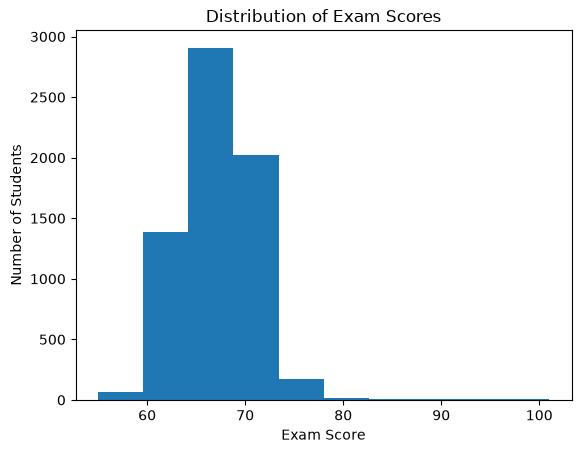

In [21]:
plt.hist(df["Exam_Score"], bins=10)
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.title("Distribution of Exam Scores")
plt.show()


In [22]:
parental_scores = df.groupby("Parental_Involvement")["Exam_Score"].mean()
parental_scores

Parental_Involvement
High      68.092767
Low       66.358265
Medium    67.098156
Name: Exam_Score, dtype: float64

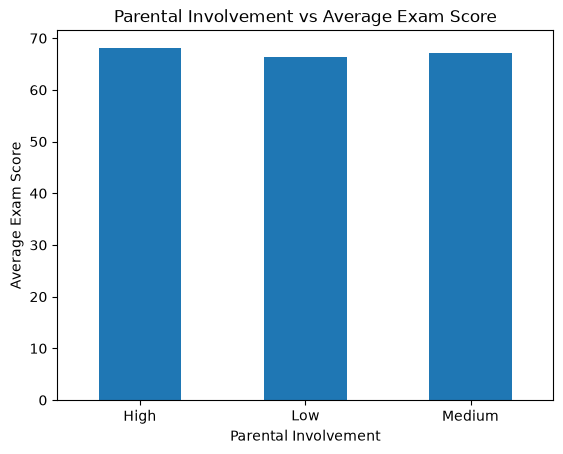

In [23]:
parental_scores.plot(kind="bar")
plt.xlabel("Parental Involvement")
plt.ylabel("Average Exam Score")
plt.title("Parental Involvement vs Average Exam Score")
plt.xticks(rotation=0)
plt.show()

In [24]:
resources_scores = df.groupby("Access_to_Resources")["Exam_Score"].mean()
resources_scores

Access_to_Resources
High      68.092152
Low       66.203351
Medium    67.134378
Name: Exam_Score, dtype: float64

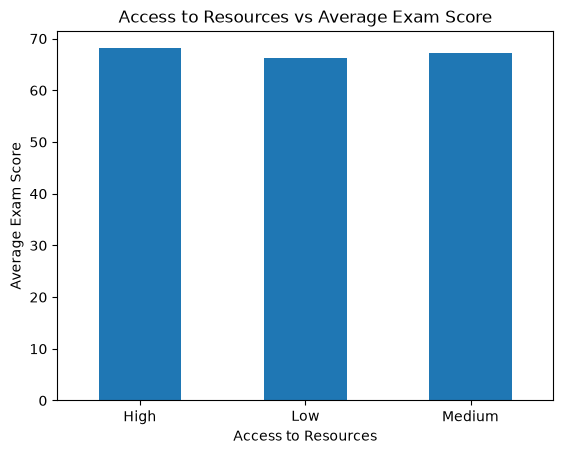

In [25]:
resources_scores.plot(kind="bar")
plt.xlabel("Access to Resources")
plt.ylabel("Average Exam Score")
plt.title("Access to Resources vs Average Exam Score")
plt.xticks(rotation=0)
plt.show()

In [26]:
df["Attendance_Group"] = pd.cut(
    df["Attendance"],
    bins=[59, 70, 80, 90, 100],
    labels=["60-70", "71-80", "81-90", "91-100"]
)

attendance_scores = df.groupby(
    "Attendance_Group", observed=True
)["Exam_Score"].mean()

attendance_scores

Attendance_Group
60-70     64.330450
71-80     66.431616
81-90     68.335634
91-100    70.155346
Name: Exam_Score, dtype: float64

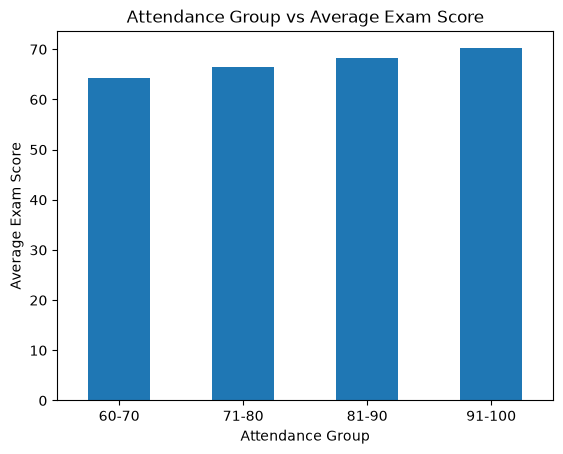

In [27]:
attendance_scores.plot(kind="bar")
plt.xlabel("Attendance Group")
plt.ylabel("Average Exam Score")
plt.title("Attendance Group vs Average Exam Score")
plt.xticks(rotation=0)
plt.show()

In [28]:
df["Study_Hours_Group"] = pd.cut(
    df["Hours_Studied"],
    bins=[0, 10, 20, 30, 50],
    labels=["1-10", "11-20", "21-30", "31-44"]
)

study_hours_scores = df.groupby(
    "Study_Hours_Group", observed=True
)["Exam_Score"].mean()

study_hours_scores

Study_Hours_Group
1-10     63.967123
11-20    66.177729
21-30    68.517082
31-44    71.011858
Name: Exam_Score, dtype: float64

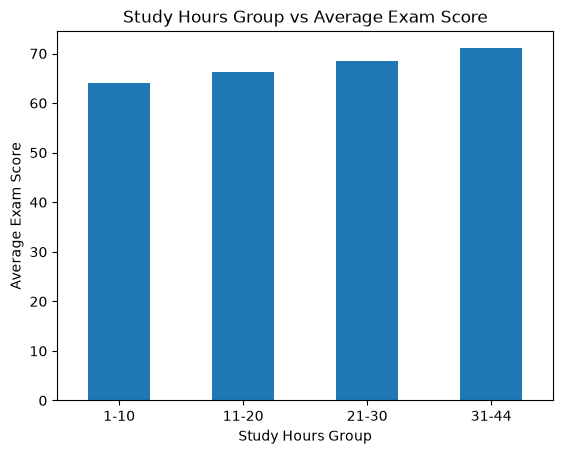

In [29]:
study_hours_scores.plot(kind="bar")
plt.xlabel("Study Hours Group")
plt.ylabel("Average Exam Score")
plt.title("Study Hours Group vs Average Exam Score")
plt.xticks(rotation=0)
plt.show()

In [30]:
df.to_csv("../dataset/student_performance_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


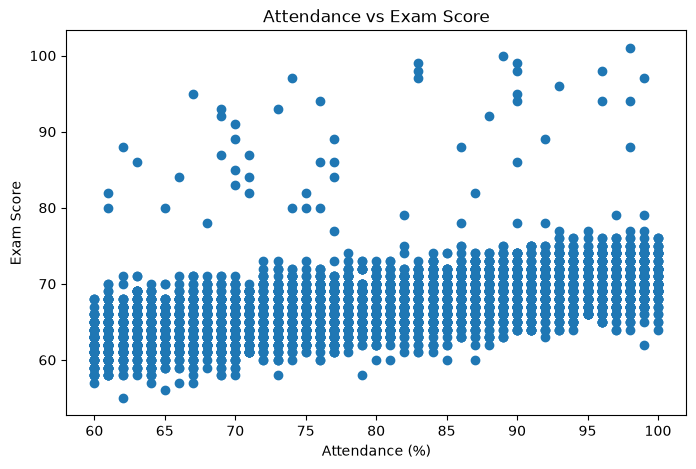

In [31]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Attendance"], df["Exam_Score"])
plt.xlabel("Attendance (%)")
plt.ylabel("Exam Score")
plt.title("Attendance vs Exam Score")
plt.savefig("../visualizations/attendance_vs_exam_score.png", dpi=300, bbox_inches="tight")
plt.show()

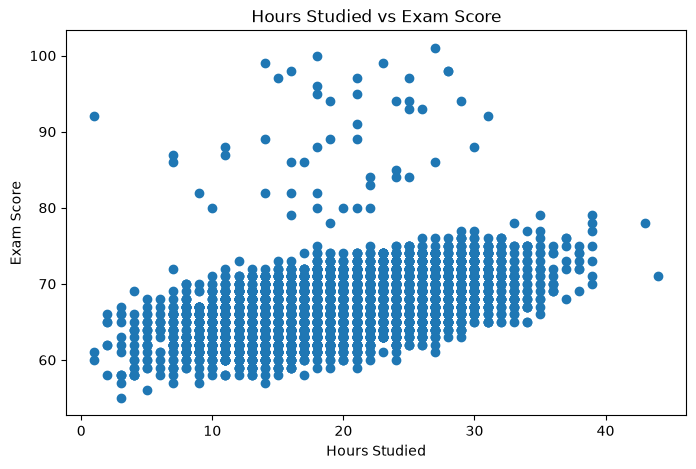

In [32]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Hours_Studied"], df["Exam_Score"])
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Hours Studied vs Exam Score")
plt.savefig("../visualizations/hours_studied_vs_exam_score.png", dpi=300, bbox_inches="tight")
plt.show()

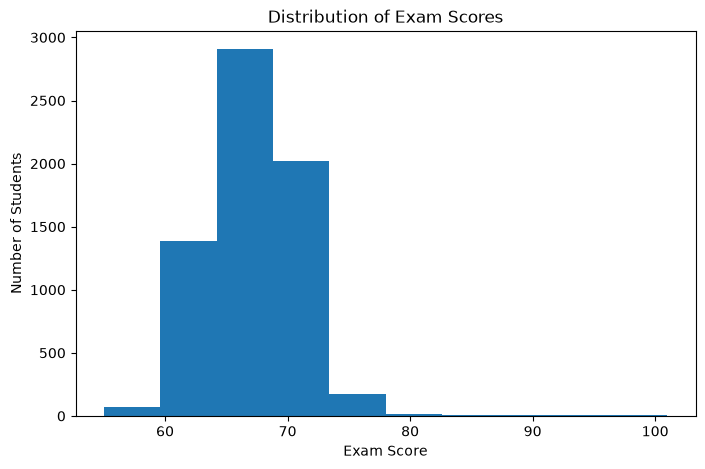

In [33]:
plt.figure(figsize=(8, 5))
plt.hist(df["Exam_Score"], bins=10)
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.title("Distribution of Exam Scores")
plt.savefig("../visualizations/exam_score_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

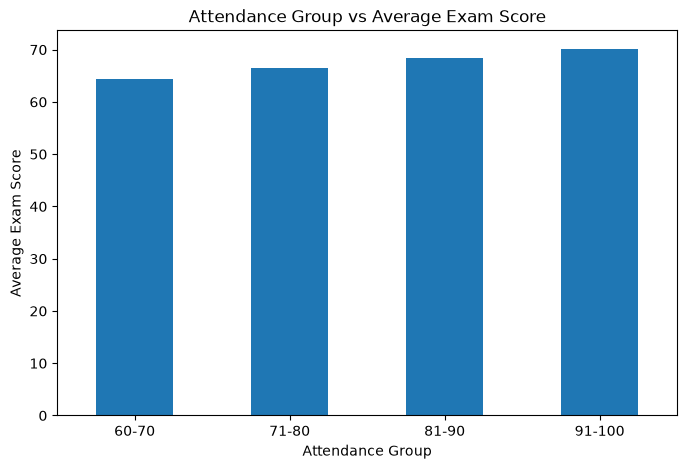

In [34]:
plt.figure(figsize=(8, 5))
attendance_scores.plot(kind="bar")
plt.xlabel("Attendance Group")
plt.ylabel("Average Exam Score")
plt.title("Attendance Group vs Average Exam Score")
plt.xticks(rotation=0)
plt.savefig("../visualizations/attendance_group_vs_exam_score.png", dpi=300, bbox_inches="tight")
plt.show()

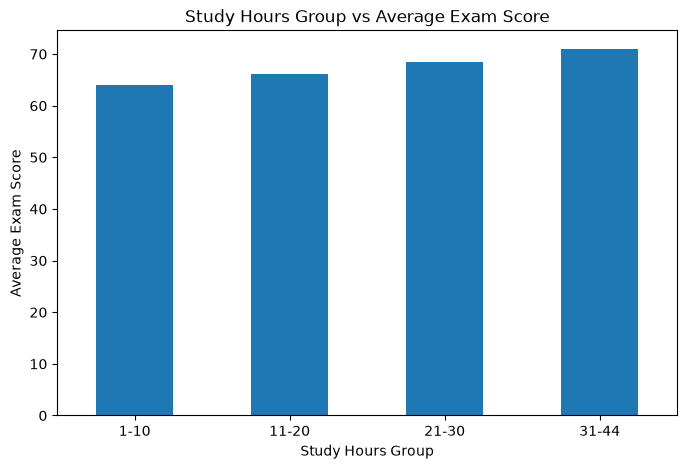

In [35]:
plt.figure(figsize=(8, 5))
study_hours_scores.plot(kind="bar")
plt.xlabel("Study Hours Group")
plt.ylabel("Average Exam Score")
plt.title("Study Hours Group vs Average Exam Score")
plt.xticks(rotation=0)
plt.savefig("../visualizations/study_hours_group_vs_exam_score.png", dpi=300, bbox_inches="tight")
plt.show()

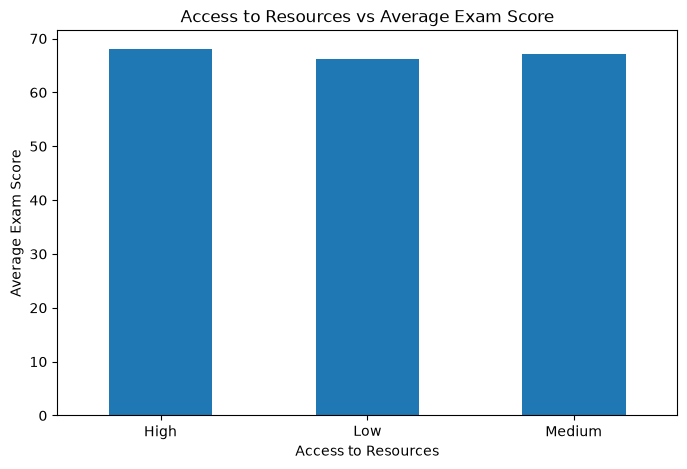

In [36]:
plt.figure(figsize=(8, 5))
resources_scores.plot(kind="bar")
plt.xlabel("Access to Resources")
plt.ylabel("Average Exam Score")
plt.title("Access to Resources vs Average Exam Score")
plt.xticks(rotation=0)
plt.savefig("../visualizations/access_to_resources_vs_exam_score.png", dpi=300, bbox_inches="tight")
plt.show()

In [37]:
df[["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]].corr()

,Hours_Studied,Attendance,Previous_Scores,Exam_Score
Hours_Studied,1.000000,-0.009908,0.024846,0.445455
Attendance,-0.009908,1.000000,-0.020186,0.581072
Previous_Scores,0.024846,-0.020186,1.000000,0.175079
Exam_Score,0.445455,0.581072,0.175079,1.000000


# Final Insights

1. **Attendance has the strongest relationship with exam scores.** The correlation between attendance and exam score is **0.581**, showing a moderate positive relationship.

2. **Study hours also have a positive relationship with exam performance.** The correlation is **0.445**, and students who studied more hours generally achieved higher average exam scores.

3. **Previous scores have a weak relationship with current exam scores.** The correlation is **0.175**, indicating that previous performance alone is not a strong indicator.

4. **Access to resources shows a positive difference in average scores.** Students with high access to resources had an average score of about **68.09**, compared with **66.20** for students with low access.

5. **Parental involvement shows a small positive difference.** Students with high parental involvement had an average score of about **68.09**, compared with **66.36** for low involvement.

6. **Motivation level shows only a small difference in this dataset.** Average scores were approximately **67.70** for high motivation and **66.75** for low motivation.

7. The overall average exam score in the dataset is approximately **67.24**.

# Recommendations

* Students should maintain **regular attendance** to support better academic performance.
* Students should follow a **consistent study schedule** and increase productive study time.
* Schools should provide students with **adequate learning resources**.
* Parents can provide **regular academic support and encouragement**.
* Previous academic performance should be considered along with other factors rather than being used as the only indicator.
* Student performance should be analyzed using **multiple factors together** instead of relying on a single factor.

**Note:** These findings show relationships and patterns in the dataset. Correlation does not necessarily mean that one factor directly causes another.


# Conclusion

This project analyzed student performance using factors such as attendance, study hours, previous scores, parental involvement, motivation, and access to resources.

The analysis showed that **attendance and study hours have the strongest positive relationships with exam scores** among the factors analyzed. The results also showed smaller differences based on parental involvement, access to resources, and motivation.

Overall, the analysis helps identify important patterns that can be useful for understanding and improving student academic performance.
